# Analysis of power change fits

In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"
PLOT_DIR_NEW.mkdir(exist_ok=True)

In [3]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_power_change_vehicle.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_power_change_empa.nc")
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["power_change_vehicle"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["power_change_empa"])

In [4]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-0.317,0.257,-0.810,0.154,0.007,0.005,1502.0,2149.0,1.00
activity_type[single],-0.081,0.077,-0.219,0.069,0.001,0.001,3512.0,2794.0,1.00
gtyp[fa/fa],0.263,0.372,-0.420,0.966,0.010,0.007,1436.0,2119.0,1.00
age[Young],0.020,0.360,-0.686,0.671,0.009,0.006,1591.0,2410.0,1.00
sex[M],0.160,0.340,-0.474,0.800,0.008,0.008,1795.0,1586.0,1.01
"gtyp:age[fa/fa, Young]",-0.083,0.514,-1.033,0.896,0.013,0.009,1512.0,2269.0,1.00
"gtyp:sex[fa/fa, M]",-0.325,0.499,-1.238,0.651,0.012,0.011,1722.0,1862.0,1.00
1|rat_sigma,0.659,0.107,0.480,0.864,0.003,0.002,1073.0,1554.0,1.00


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,-1.107,0.351,-1.760,-0.427,0.009,0.006,1595.0,1930.0,1.0
activity_type[single],0.220,0.097,0.030,0.398,0.002,0.002,4140.0,2529.0,1.0
gtyp[fa/fa],0.481,0.508,-0.436,1.466,0.013,0.009,1470.0,2004.0,1.0
age[Young],0.332,0.500,-0.616,1.311,0.011,0.010,1908.0,2101.0,1.0
sex[M],-1.006,0.483,-1.928,-0.140,0.011,0.009,1996.0,2324.0,1.0
"gtyp:age[fa/fa, Young]",-0.795,0.730,-2.190,0.531,0.018,0.017,1729.0,2121.0,1.0
"gtyp:sex[fa/fa, M]",0.863,0.701,-0.402,2.237,0.015,0.012,2094.0,2404.0,1.0
1|rat_sigma,0.909,0.143,0.657,1.171,0.004,0.003,1125.0,1920.0,1.0


## Posterior predictive checks

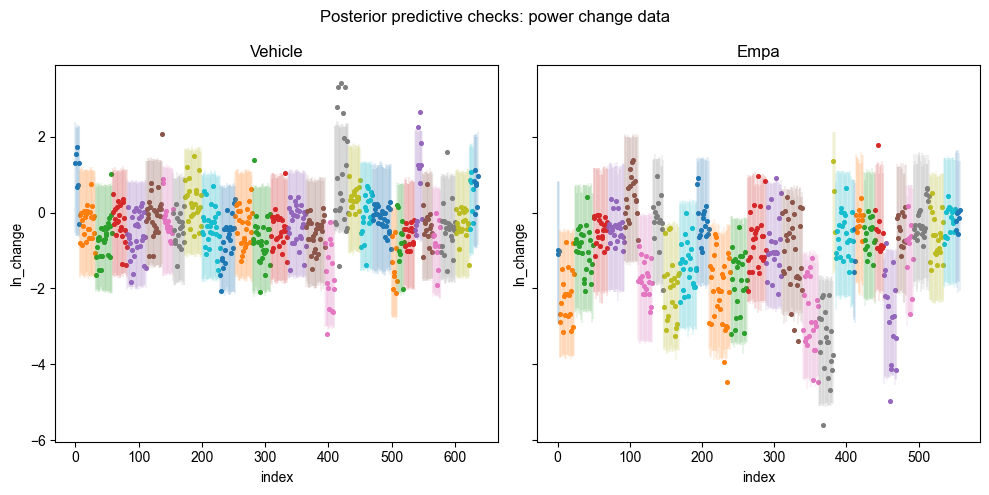

In [5]:
f, axes = plt.subplots(1, 2, figsize=[10, 5], sharey=True)
for ax, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    ax = plot_ppc(ax, idata, msts, ycol="ln_change", groupcol="rat")
    ax.set_title(name.capitalize());
    ax.get_legend().remove()

f.suptitle("Posterior predictive checks: power change data");
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_power_change.png", bbox_inches="tight", dpi=200)

Each dot is a vessel, sorted by rat; lines are 1%-99% posterior predictive intervals.

## Effects

Contrasts follow the brief. The overall effect of a factor is averaged with equal weights over the levels of the other factors, e.g. the overall gtyp effect is the mean of fa/fa - fa/+ over the four age/sex groups. The gtyp effect given sex is averaged over age, and vice versa. SP is the posterior probability that the contrast is positive; lines are 95% intervals.

In [6]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="TS (ln injected/baseline)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))
overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups) | {
        # activity_type's reference level is double, so negate to get double - single
        "double - single": -idata.posterior["activity_type"].sel(activity_type_dim="single", drop=True),
    }
    for idata, t_groups in ((idata_vehicle, t_groups_vehicle), (idata_empa, t_groups_empa))
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))

### Overall effects

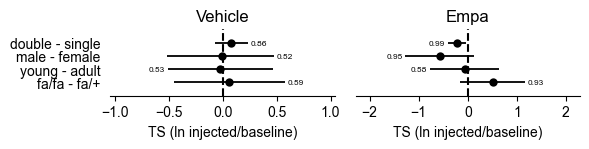

In [7]:
f, axes = plot_effects(overall_ts_vehicle, overall_ts_empa, figsize=(6, 1.6))
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_power_change_overall.png", bbox_inches="tight", dpi=200)

### Effect of gtyp given sex and given age

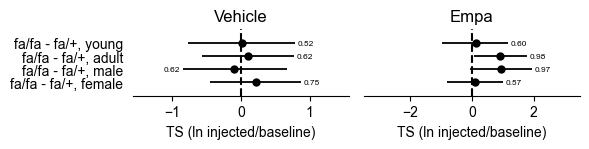

In [8]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(6, 1.6))
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_power_change_gtyp_given_sex_age.png", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [9]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (overall_ts_vehicle, overall_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
        )
    ],
    keys=("overall", "gtyp given sex/age"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif     empa  \
contrast           group                                                   
overall            fa/fa - fa/+          0.58650                 0.93450   
                   young - adult         0.47175                 0.41900   
                   male - female         0.51625                 0.04950   
                   double - single       0.86025                 0.01375   
gtyp given sex/age fa/fa - fa/+, female  0.75150                 0.56600   
                   fa/fa - fa/+, male    0.37900                 0.96700   
                   fa/fa - fa/+, adult   0.62000                 0.97975   
                   fa/fa - fa/+, young   0.52425                 0.60025   

                                        empa_signif  
contrast           group                             
overall            fa/fa - fa/+                      
                   young - adult                     
                   male - female                     
                   double - single                *  
gtyp given sex/age fa/fa - fa/+, female              
                   fa/fa - fa/+, male                
                   fa/fa - fa/+, adult            *  
                   fa/fa - fa/+, young